# CPICS Batch Classification Pipeline

This Jupyter Notebook automates the high-throughput classification of plankton imagery collected by CPICS (Continuous Plankton Imaging and Classification Sensor). It acts as a wrapper around the `Image_Classification.py` script, allowing users to process multiple image collections iteratively based on a defined date range, and compiles the results into a single, comprehensive master dataset.

## What This Notebook Does

1. **Date Filtering:** Scans the raw image directory and selects CPICS collection folders that fall within a user-defined date range (e.g., `2022-12-01` to `2024-11-30`).
2. **Data Staging:** Automatically empties the temporary staging directory and copies all `.png` files from the current target collection into it.
3. **Automated Classification:** Executes the PyTorch/ResNet-152 model via the `Image_Classification.py` script to generate a `predictions.csv` for the staged images.
4. **Master Compilation:** Appends the results of each collection's classification into a master Pandas DataFrame, tracking the source collection for each record.
5. **Final Output:** Exports a finalized `master_predictions_filtered_range.csv` containing all classified ROIs across all processed dates.

## Prerequisites and Directory Structure

The notebook assumes the following file structure exists in your home directory (`~/`). It relies on the collection folders being named using the `YYYYMMDD` format (e.g., `20221204`).

```text
~/plankton_imaging/
│
├── Image_Classification.py                 # The core PyTorch classification script
│
├── cpics_img/                              # Raw CPICS collections (Source)
│   ├── 20221204/
│   ├── 20221205/
│   └── ...
│
├── unclassified_dataset/                   # Temporary staging area
│   └── unclassified/                       # (Notebook will clear and fill this)
│
└── classified_output/                      # Final output directory
    ├── predictions.csv                     # Overwritten each loop
    └── master_predictions_filtered_range.csv # Final compiled output
```

## Dependencies

### 1. Notebook Dependencies
To run the Jupyter Notebook itself, you need the following standard Python libraries:
* `pandas` (for date parsing and CSV compilation)
* `tqdm` (specifically `tqdm.notebook` for progress bars)
* Standard libraries: `os`, `shutil`, `pathlib`, `subprocess`

You can install the required external packages via:
`pip install pandas tqdm`

### 2. Upstream Script Dependencies
Because this notebook triggers `Image_Classification.py`, the active Python environment must also support the machine learning script. Ensure the following are installed and configured (preferably with CUDA/GPU support):
* `torch` (PyTorch)
* `torchvision`
* `opencv-python` (`cv2`)
* `Pillow` (`PIL`)
* `numpy`

## Usage Instructions

1. Open the notebook in Jupyter or VS Code.
2. Under the **Configuration** section, adjust the `start_date` and `end_date` variables to match your desired analysis window.
3. Verify that `base_dir` correctly points to your `plankton_imaging` folder.
4. Run the cell. The progress bar will update as it processes each daily/hourly collection folder, and the final CSV will be deposited in the `classified_output` directory.

In [ ]:
import os
import shutil
import pandas as pd
from pathlib import Path
import subprocess
import sys
from PIL import Image
from tqdm import tqdm

# --- 1. Configuration ---
base_dir = Path(os.path.expanduser("~/plankton_imaging"))
cpics_img_dir = base_dir / "cpics_img"
unclassified_dir = base_dir / "unclassified_dataset" / "unclassified"
classified_out_dir = base_dir / "classified_output"
script_path = base_dir / "Classifier" / "Image_Classification.py"
master_csv_path = classified_out_dir / "master_predictions_filtered_range.csv"

start_date = pd.Timestamp("2022-12-01")
end_date = pd.Timestamp("2024-12-01")

# --- 2. Filter Collections ---
collections = []
for d in cpics_img_dir.iterdir():
    if d.is_dir() and not d.name.startswith('.'):
        try:
            folder_date = pd.to_datetime(d.name[:8], format="%Y%m%d")
            if start_date <= folder_date <= end_date:
                collections.append(d.name)
        except ValueError:
            pass

collections.sort()
print(f"Found {len(collections)} collections to process between {start_date.date()} and {end_date.date()}:")

already_processed = set()
if master_csv_path.exists():
    try:
        existing_df = pd.read_csv(master_csv_path, usecols=['source_collection'])
        already_processed = set(existing_df['source_collection'].unique())
        print(f"Resuming: {len(already_processed)} collections already completed.")
    except Exception as e:
        print(f"Could not read existing master CSV: {e}")

# --- 3. Iterative Processing ---
for collection in tqdm(collections, desc="Processing CPICS Collections"):
    if collection in already_processed:
        print(f"\n--- Skipping {collection} (already recorded) ---")
        continue

    print(f"\n--- Processing Collection: {collection} ---")
    
    # Step A: Empty staging folder
    unclassified_dir.mkdir(parents=True, exist_ok=True)
    for item in unclassified_dir.iterdir():
        if item.is_file():
            item.unlink()
            
    # Step B: Copy only valid PNG files
    collection_path = cpics_img_dir / collection
    png_files = list(collection_path.rglob("*.png"))
    
    if not png_files:
        print(f"  -> No PNG files found in {collection}. Skipping...")
        continue
        
    valid_count = 0
    for file_path in png_files:
        # Guard against zero-byte files
        if file_path.stat().st_size == 0:
            continue
        try:
            # Verify file integrity header quickly
            with Image.open(file_path) as im:
                im.verify()
            shutil.copy(file_path, unclassified_dir)
            valid_count += 1
        except Exception:
            # Corrupted image, do not copy to staging
            continue

    if valid_count == 0:
        print(f"  -> No valid non-corrupt images in {collection}. Skipping...")
        continue

    print(f"  -> Copied {valid_count} valid files to staging.")
        
    # Step C: Run classifier
    print(f"  -> Running Image_Classification.py...")
    result = subprocess.run([sys.executable, str(script_path)], capture_output=True, text=True)
    
    if result.returncode != 0:
        print(f"  -> Error running classification for {collection}:")
        print(result.stderr)
        continue
        
    # Step D: Save output immediately
    pred_csv = classified_out_dir / "predictions.csv"
    if pred_csv.exists():
        df = pd.read_csv(pred_csv)
        df['source_collection'] = collection
        
        # Backup collection-level CSV
        df.to_csv(classified_out_dir / f"predictions_{collection}.csv", index=False)
        
        # Append to cumulative master CSV
        header_needed = not master_csv_path.exists()
        df.to_csv(master_csv_path, mode='a', header=header_needed, index=False)
        already_processed.add(collection)
        print(f"  -> Successfully recorded {len(df)} records to master CSV.")
    else:
        print(f"  -> Warning: predictions.csv not generated for {collection}.")

print("\nWorkflow completed!")

In [ ]:
import pandas as pd
from pathlib import Path

# Define paths
classified_out_dir = Path("~/plankton_imaging/classified_output").expanduser()
master_csv_path = classified_out_dir / "master_predictions_filtered_range.csv"

# 1. Count total PNG files in the classified_output directory (including subfolders)
png_count = sum(1 for _ in classified_out_dir.rglob("*.png"))

# 2. Count total records in the master CSV file
csv_rows = 0
if master_csv_path.exists():
    # Read only the first column to optimize memory usage
    df = pd.read_csv(master_csv_path, usecols=[0])
    csv_rows = len(df)
else:
    print(f"Warning: {master_csv_path.name} does not exist yet.")

# Print the comparison
print("--- Validation Check ---")
print(f"Total PNG files on disk:  {png_count}")
print(f"Total records in master CSV: {csv_rows}")

if png_count == csv_rows and png_count > 0:
    print("\nStatus: MATCH! The number of saved images perfectly matches the CSV records.")
elif png_count != csv_rows and png_count > 0:
    print(f"\nStatus: MISMATCH. Difference of {abs(png_count - csv_rows)} items.")

Scanning /home/enrique.montes@CNS.local/plankton_imaging/classified_output...
Scanning /home/enrique.montes@CNS.local/plankton_imaging/classified_output_filtered...


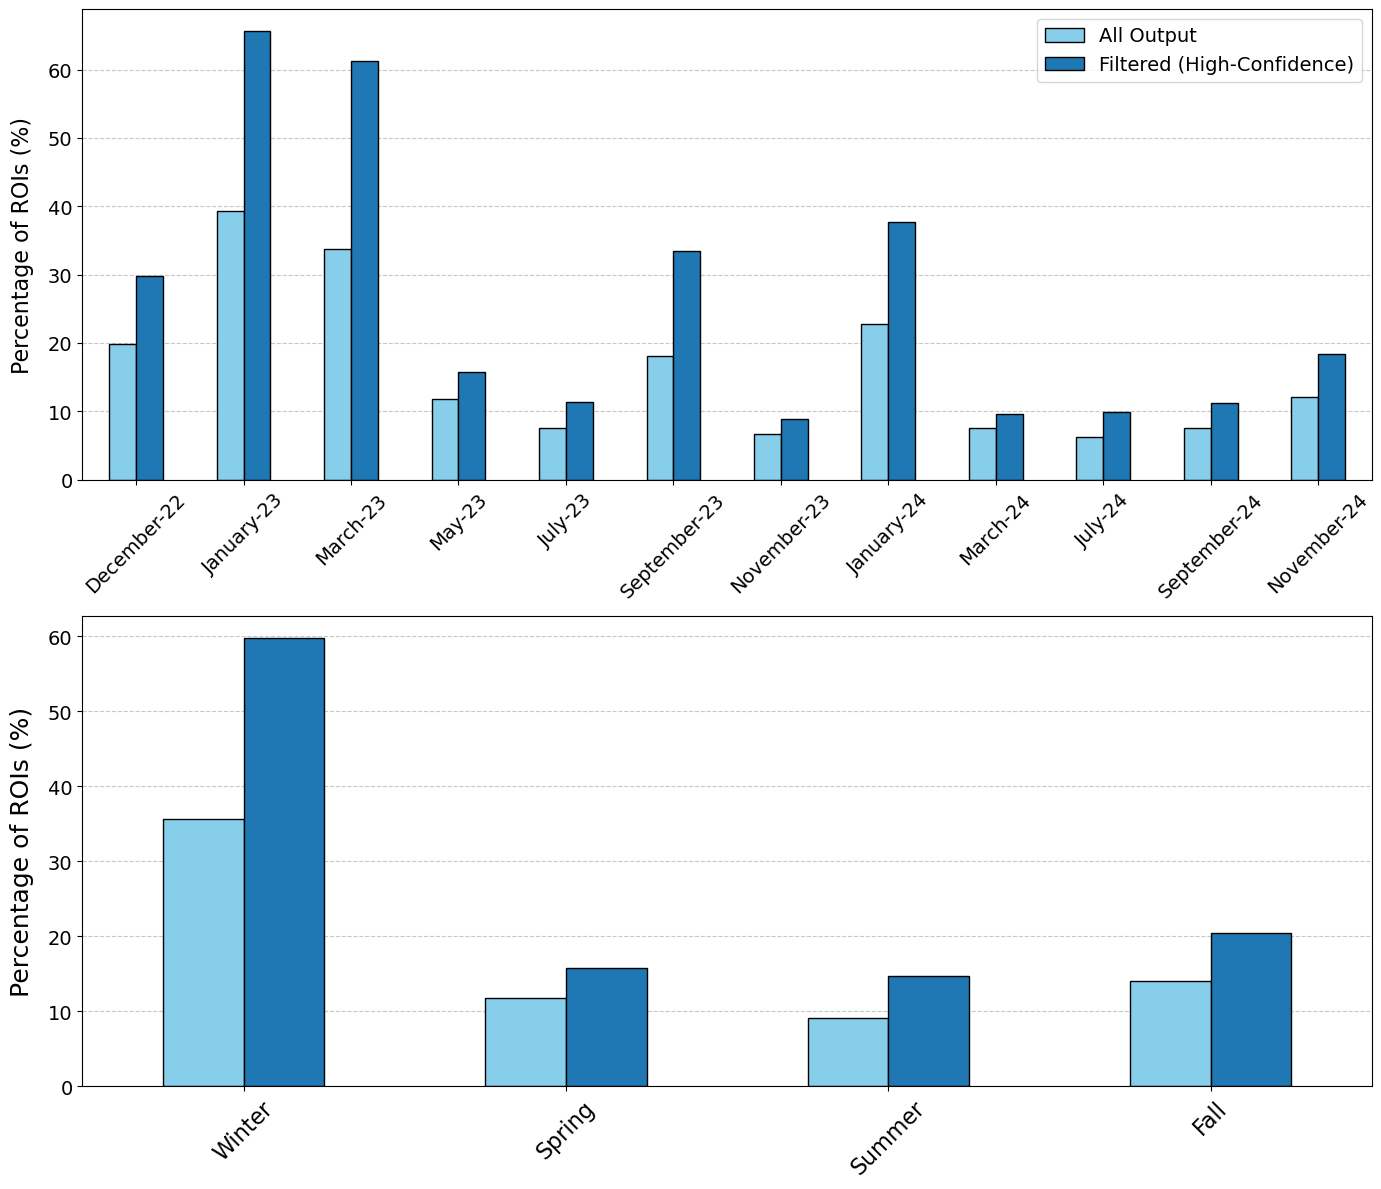


--- Summary ---
All Output: 82027 bubbles out of 327651 total images (25.03%).
Filtered (High-Confidence): 44937 bubbles out of 118372 total images (37.96%).


In [38]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# --- 1. Scan Directories and Extract Data ---
directories = {
    'All Output': Path("~/plankton_imaging/classified_output").expanduser(),
    'Filtered (High-Confidence)': Path("~/plankton_imaging/classified_output_filtered").expanduser()
}

data = []
for ds_name, dir_path in directories.items():
    print(f"Scanning {dir_path}...")
    # Iterate through all PNG files in all subdirectories
    for img_path in dir_path.rglob("*.png"):
        class_name = img_path.parent.name
        date_str = img_path.name[:8]
        data.append({"class": class_name, "date_str": date_str, "dataset": ds_name})

if not data:
    print("No PNG files found in the specified directories.")
else:
    # --- 2. Build DataFrame and Parse Dates ---
    df = pd.DataFrame(data)
    
    # Convert string to datetime
    df['date'] = pd.to_datetime(df['date_str'], format='%Y%m%d', errors='coerce')
    df = df.dropna(subset=['date'])
    
    # Create MMMM-YY and Season columns
    df['month_yr'] = df['date'].dt.strftime('%B-%y')
    
    def get_season(month):
        if month in [1, 2, 3]: return 'Winter'
        elif month in [4, 5, 6]: return 'Spring'
        elif month in [7, 8, 9]: return 'Summer'
        elif month in [10, 11, 12]: return 'Fall'
        
    df['season'] = df['date'].dt.month.map(get_season)

    # --- 3. Calculate Percentages ---
    # Group by both the time period and the dataset origin
    
    # Monthly calculations
    monthly_totals = df.groupby(['month_yr', 'dataset']).size().unstack(fill_value=0)
    bubbles_monthly = df[df['class'] == 'bubbles'].groupby(['month_yr', 'dataset']).size().unstack(fill_value=0)
    
    # Align indices to ensure no missing months, then calculate percentage
    bubbles_monthly = bubbles_monthly.reindex(monthly_totals.index, fill_value=0)
    monthly_percent = (bubbles_monthly / monthly_totals * 100).fillna(0)

    # Sort months chronologically rather than alphabetically
    ordered_months = df.sort_values('date')['month_yr'].unique()
    monthly_percent = monthly_percent.reindex(ordered_months)

    # Seasonal calculations
    seasonal_totals = df.groupby(['season', 'dataset']).size().unstack(fill_value=0)
    bubbles_seasonal = df[df['class'] == 'bubbles'].groupby(['season', 'dataset']).size().unstack(fill_value=0)
    
    bubbles_seasonal = bubbles_seasonal.reindex(seasonal_totals.index, fill_value=0)
    seasonal_percent = (bubbles_seasonal / seasonal_totals * 100).fillna(0)

    # Order seasons chronologically
    season_order = ['Winter', 'Spring', 'Summer', 'Fall']
    season_order = [s for s in season_order if s in seasonal_percent.index]
    seasonal_percent = seasonal_percent.reindex(season_order)

    # --- 4. Render Grouped Bar Plots ---
    fig, axes = plt.subplots(2, 1, figsize=(14, 12))
    
    colors = ['#87CEEB', '#1f77b4'] # Light blue for All, Dark blue for Filtered

    # Plot 1: MMMM-YY Bar Plot
    monthly_percent.plot(kind='bar', ax=axes[0], color=colors, edgecolor='black', zorder=2)
    # axes[0].set_title('Monthly Proportion of Bubbles: All vs High-Confidence (MMMM-YY)', fontsize=14, pad=10)
    axes[0].set_ylabel('Percentage of ROIs (%)', fontsize=16, labelpad=10)
    axes[0].set_xlabel('')
    axes[0].tick_params(axis='x', rotation=45, labelsize=14)
    axes[0].tick_params(axis='y', labelsize=14)
    axes[0].grid(axis='y', linestyle='--', alpha=0.7, zorder=1)
    axes[0].legend(fontsize=14, loc='upper right')

    # Plot 2: Seasonal Bar Plot
    seasonal_percent.plot(kind='bar', ax=axes[1], color=colors, edgecolor='black', zorder=2)
    # axes[1].set_title('Seasonal Proportion of Bubbles: All vs High-Confidence', fontsize=14, pad=10)
    axes[1].set_ylabel('Percentage of ROIs (%)', fontsize=18, labelpad=10)
    axes[1].set_xlabel('')
    axes[1].tick_params(axis='x', rotation=45, labelsize=16)
    axes[1].tick_params(axis='y', labelsize=14)
    axes[1].grid(axis='y', linestyle='--', alpha=0.7, zorder=1)
    axes[1].get_legend().remove()

    plt.tight_layout()
    plt.show()
    
    # Print summary statistics
    print("\n--- Summary ---")
    for ds_name in directories.keys():
        subset = df[df['dataset'] == ds_name]
        total_imgs = len(subset)
        total_bubbles = subset['class'].eq('bubbles').sum()
        print(f"{ds_name}: {total_bubbles} bubbles out of {total_imgs} total images ({(total_bubbles/total_imgs*100):.2f}%).")


--- Bubble Area Ranges per Size Class (px²) ---
Small: 1440 - 4224
Medium: 4256 - 9504
Large: 9568 - 5737760
-----------------------------------------------



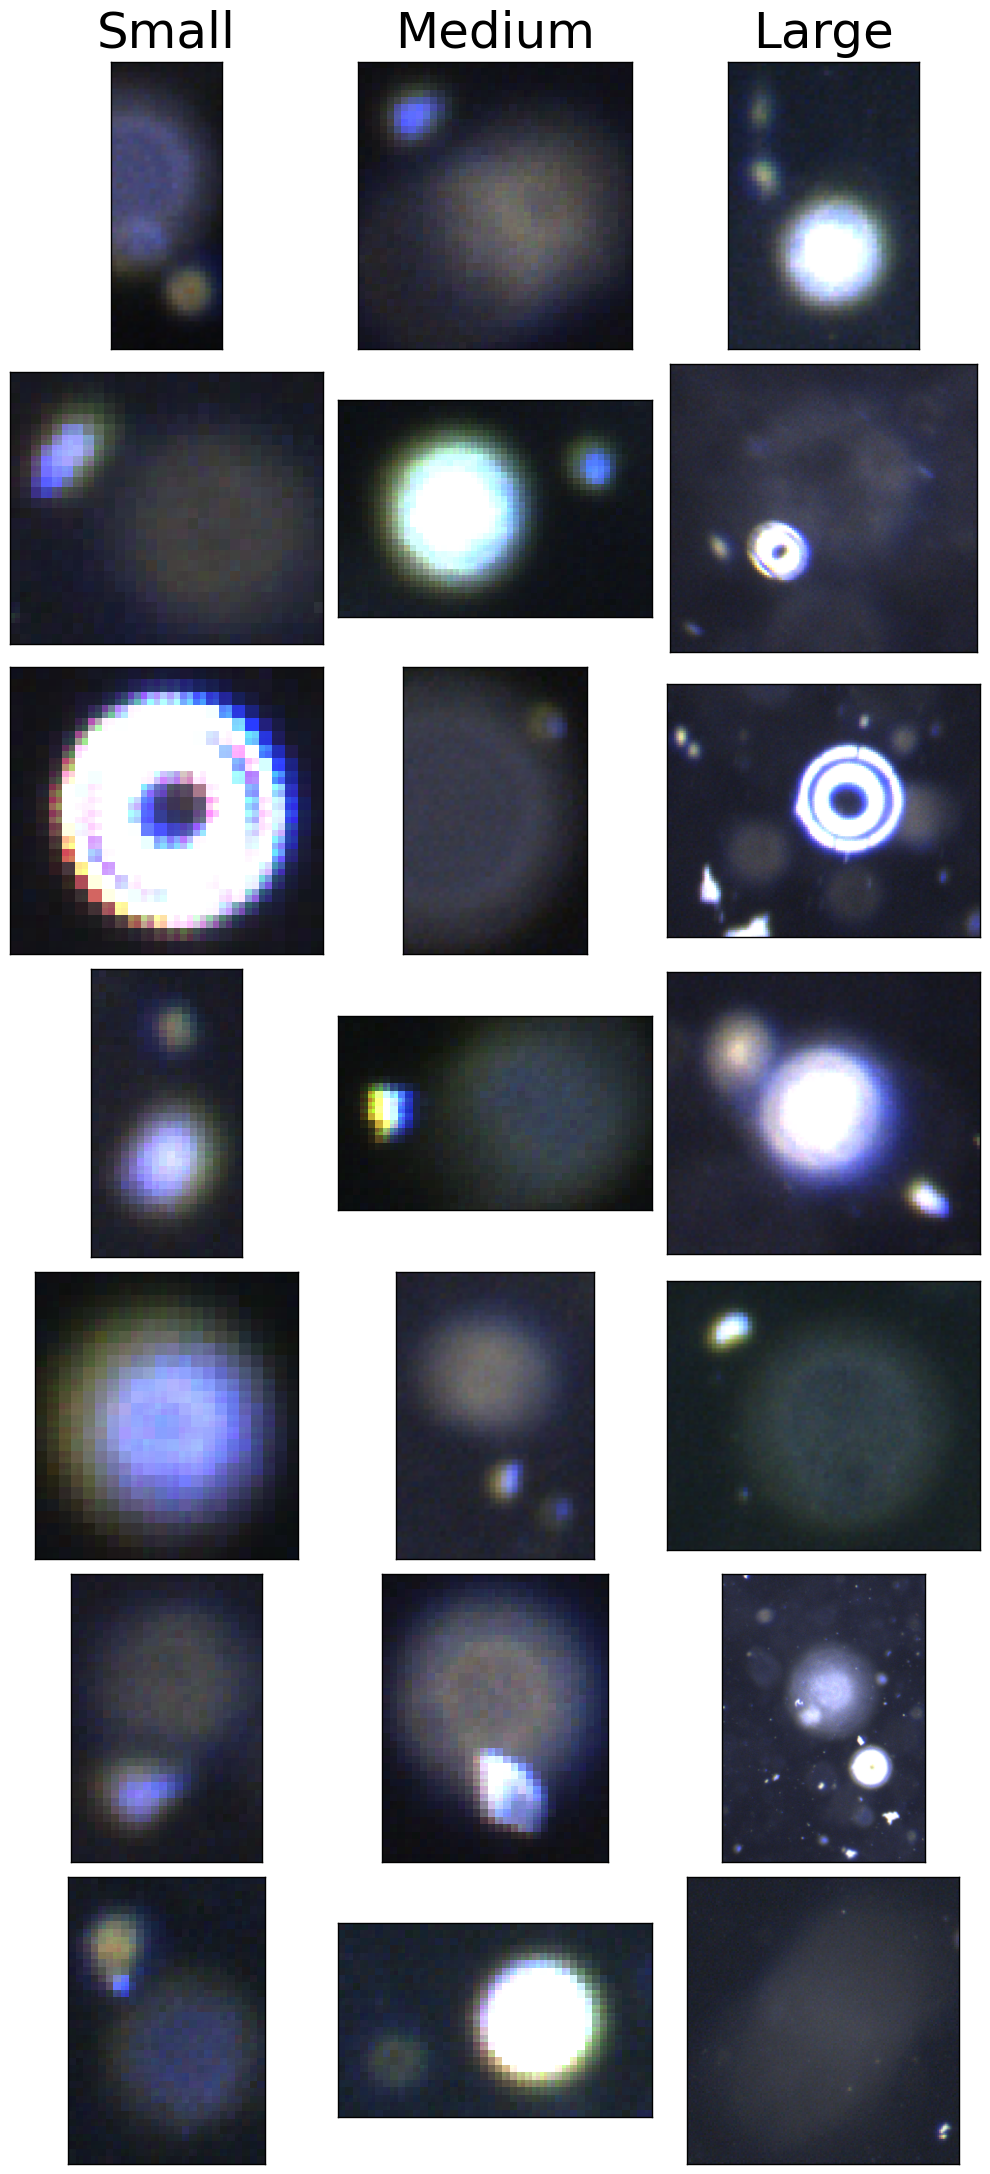

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# --- 1. Load Data & Set Parameters ---
master_csv_path = Path("~/plankton_imaging/classified_output/master_predictions_filtered_range.csv").expanduser()
search_dir = Path("~/plankton_imaging/classified_output_filtered/bubbles").expanduser()

# Define the confidence threshold range
min_confidence = 0.8
max_confidence = 0.9

df = pd.read_csv(master_csv_path)

# Filter for bubbles and ensure confidence column is numeric
bubbles_df = df[df['predicted_class'] == 'bubbles'].copy()
bubbles_df['confidence'] = pd.to_numeric(bubbles_df['confidence'], errors='coerce')

# --- 2. Calculate Morphometric Feature (Area) & Filter by Threshold Range ---
bubbles_df['w'] = pd.to_numeric(bubbles_df['w'], errors='coerce')
bubbles_df['h'] = pd.to_numeric(bubbles_df['h'], errors='coerce')
bubbles_df['area'] = bubbles_df['w'] * bubbles_df['h']
bubbles_df = bubbles_df.dropna(subset=['area', 'confidence'])

# Apply the confidence threshold range filter
bubbles_df = bubbles_df[(bubbles_df['confidence'] >= min_confidence) & (bubbles_df['confidence'] <= max_confidence)]

if bubbles_df.empty:
    print(f"No bubbles found meeting the confidence range of {min_confidence} - {max_confidence}.")
else:
    # --- 3. Bin into Size Categories ---
    bubbles_df['size_bin'] = pd.qcut(bubbles_df['area'], q=3, labels=['Small', 'Medium', 'Large'])

    # Calculate the minimum and maximum area for each bin
    bin_ranges = bubbles_df.groupby('size_bin', observed=True)['area'].agg(['min', 'max'])
    
    # Print the area ranges to the console
    print("\n--- Bubble Area Ranges per Size Class (px²) ---")
    for size_class in ['Small', 'Medium', 'Large']:
        min_area = int(bin_ranges.loc[size_class, 'min'])
        max_area = int(bin_ranges.loc[size_class, 'max'])
        print(f"{size_class}: {min_area} - {max_area}")
    print("-----------------------------------------------\n")

    # --- 4. Sample and Render the Image Grid ---
    n_rows = 7
    n_cols = 3
    bins = ['Small', 'Medium', 'Large']

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(10, 24))
    
    # Update title to reflect the chosen range
    # fig.suptitle(f'Bubble Morphologies by Size Class (Confidence: {min_confidence} - {max_confidence})', fontsize=18, y=0.92)

    for col_idx, size_class in enumerate(bins):
        # Set the title to just the size class name
        axes[0, col_idx].set_title(f"{size_class}", fontsize=36, pad=10)
        
        # Sort by confidence descending within the filtered range
        bin_data = bubbles_df[bubbles_df['size_bin'] == size_class].sort_values(by='confidence', ascending=False)
        
        row_idx = 0
        for _, row in bin_data.iterrows():
            if row_idx >= n_rows:
                break
                
            filename = row['file_name']
            img_search = list(search_dir.rglob(filename))
            
            if img_search:
                img_path = img_search[0]
                ax = axes[row_idx, col_idx]
                
                try:
                    with Image.open(img_path) as img:
                        img_rgb = img.convert('RGB')
                        ax.imshow(img_rgb)
                except Exception:
                    ax.text(0.5, 0.5, 'Load Error', ha='center', va='center')
                    
                ax.set_xticks([])
                ax.set_yticks([])
                for spine in ax.spines.values():
                    spine.set_edgecolor('black')
                    spine.set_linewidth(1)
                    
                row_idx += 1

        # If the folder didn't have 10 images meeting the threshold for this bin, blank out the rest
        while row_idx < n_rows:
            ax = axes[row_idx, col_idx]
            ax.axis('off')
            row_idx += 1

    plt.tight_layout(rect=[0, 0, 1, 0.91])
    plt.show()

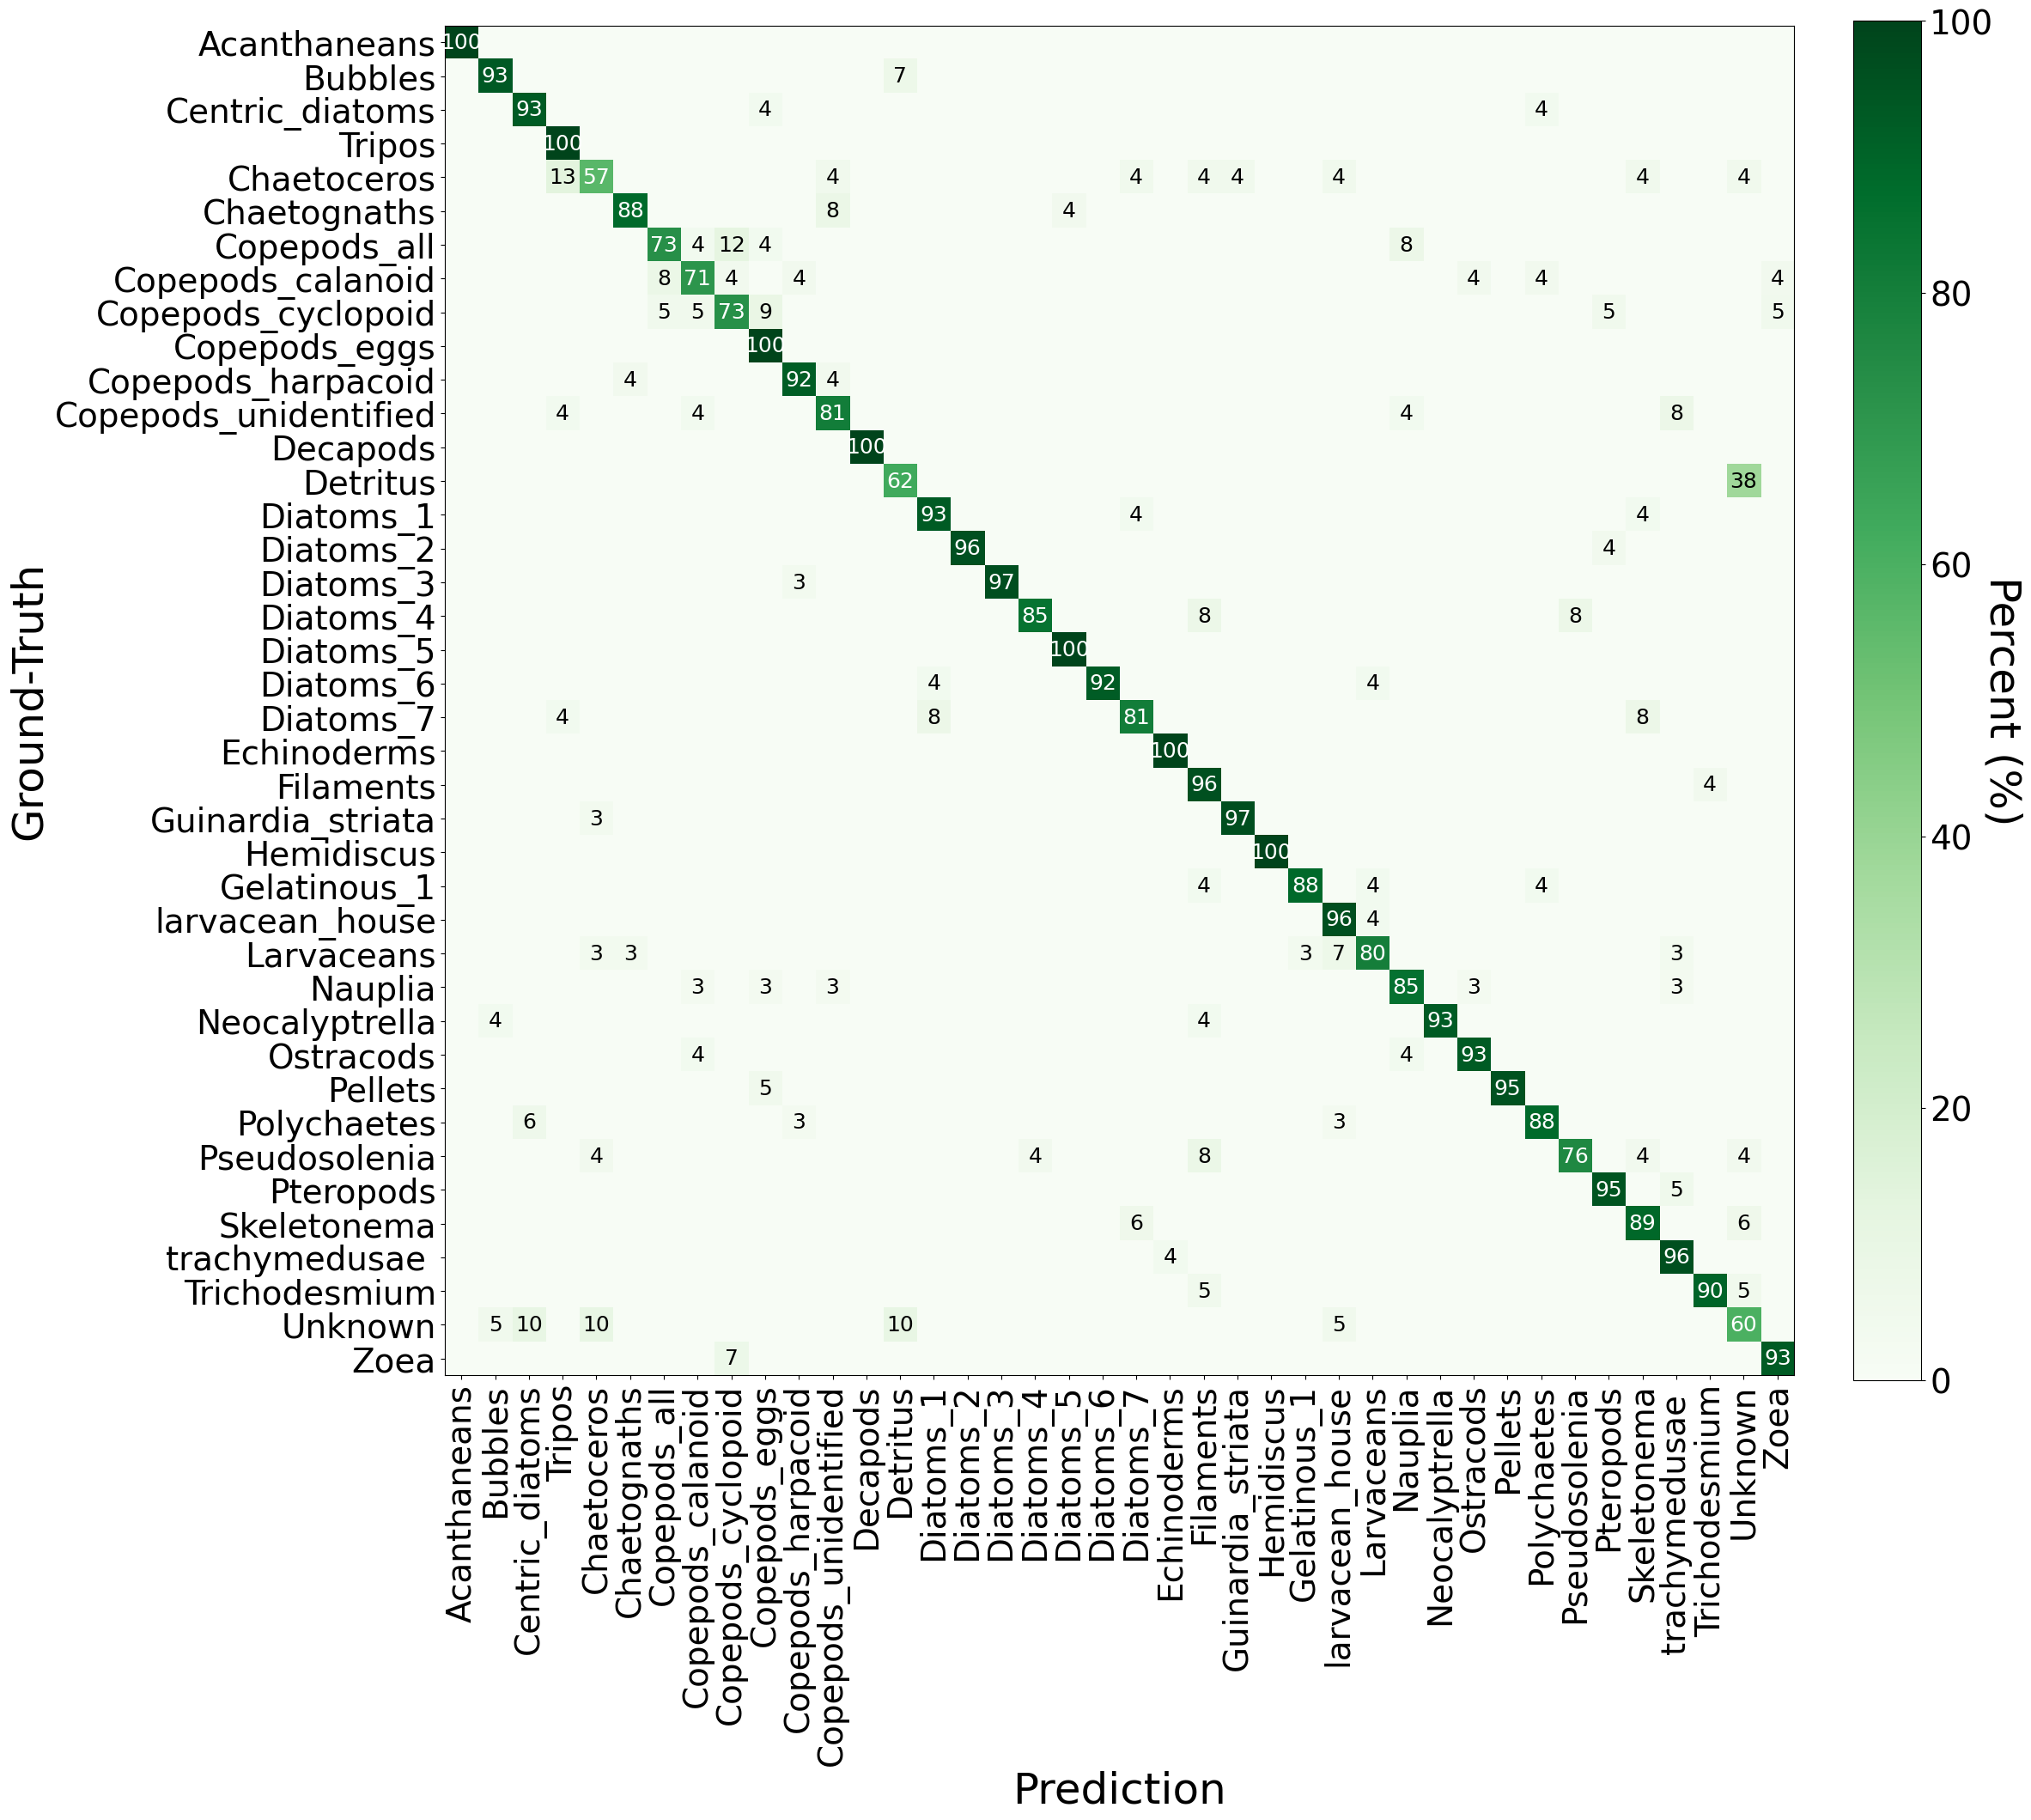

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Load the pre-computed matrix
# Be sure to use the correct path you established earlier
file_path = "/home/enrique.montes@CNS.local/plankton_imaging/models/resnet152_2025_09_02/homeenrique.montes@CNS.localplankton_imagingrandomized_balanced.csv"
df = pd.read_csv(file_path, index_col=0)

# 2. Rename the labels
label_map = {
    'acantharea': 'Acanthaneans',
    'bubbles': 'Bubbles',
    'centric': 'Centric_diatoms',
    'ceratium': 'Tripos',
    'chaetoceros': 'Chaetoceros',
    'chaetognaths': 'Chaetognaths',
    'copepods_all': 'Copepods_all',
    'copepods_calanoid': 'Copepods_calanoid',
    'copepods_calaoid': 'Copepods_calanoid', # Handling potential typo in raw data
    'copepods_cyclopoid': 'Copepods_cyclopoid',
    'copepods_eggs': 'Copepods_eggs',
    'copepods_harpacoid': 'Copepods_harpacoid',
    'copepods_x': 'Copepods_unidentified',
    'decapods': 'Decapods',
    'detritus': 'Detritus',
    'diatom_flat': 'Diatoms_1',
    'diatom_lollipop': 'Diatoms_2',
    'diatom_stephanoxis': 'Diatoms_3',
    'diatom_tubular': 'Diatoms_4',
    'diatom_x': 'Diatoms_5',
    'diatom_y': 'Diatoms_6',
    'diatom_z': 'Diatoms_7',
    'echinoderms': 'Echinoderms',
    'filaments': 'Filaments',
    'guinardia': 'Guinardia_striata',
    'hemidiscus': 'Hemidiscus',
    'jellies_y': 'Gelatinous_1',
    'larvaceans_house': 'Larvaceans_house',
    'larvaceans': 'Larvaceans',
    'nauplia': 'Nauplia',
    'neocalyptrella': 'Neocalyptrella',
    'ostracods': 'Ostracods',
    'pellets': 'Pellets',
    'polychaets': 'Polychaetes',
    'pseudosolenia': 'Pseudosolenia',
    'pteropods': 'Pteropods',
    'skeletonema': 'Skeletonema',
    'trachymedusae': 'Trachymedusae',
    'tricho': 'Trichodesmium',
    'unknown': 'Unknown',
    'zoea': 'Zoea'
}

# Apply the mapping to both rows (index) and columns
df = df.rename(index=label_map, columns=label_map)

# 3. Normalize the counts to percentages (row-wise)
row_sums = df.sum(axis=1)
cm_percentage = df.div(row_sums, axis=0) * 100
cm_percentage = cm_percentage.fillna(0)

# 4. Increase font sizes globally
plt.rcParams.update({
    'font.size': 18,          # Inside the heatmap cells
    'axes.labelsize': 36,     # Axis titles ("Prediction", "Ground-Truth")
    'xtick.labelsize': 28,    # Class names on X axis
    'ytick.labelsize': 28,    # Class names on Y axis
    'axes.titlesize': 36      # Main title
})

# 5. Render the plot using Matplotlib
fig, ax = plt.subplots(figsize=(24, 24))
cax = ax.imshow(cm_percentage, cmap="Greens")

# Add the colorbar
cbar = fig.colorbar(cax, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('Percent (%)', rotation=270, labelpad=25)

# Set the axis ticks and labels
ax.set_xticks(np.arange(len(df.columns)))
ax.set_yticks(np.arange(len(df.index)))
ax.set_xticklabels(df.columns, rotation=90)
ax.set_yticklabels(df.index)

# Add the text annotations inside the cells
for i in range(len(df.index)):
    for j in range(len(df.columns)):
        val = cm_percentage.iloc[i, j]
        if val > 0:  
            text_color = "white" if val > 50 else "black"
            ax.text(j, i, f"{val:.0f}", ha="center", va="center", color=text_color)

# Formatting
# plt.title('Normalized Confusion Matrix (%)', pad=20)
plt.ylabel('Ground-Truth')
plt.xlabel('Prediction')
plt.tight_layout()

# Save for publication
plt.savefig("high_res_confusion_matrix_updated_labels.png", dpi=300)
plt.show()